In [1]:
import pandas as pd
df = pd.read_csv('titanic_cleaned (1).csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


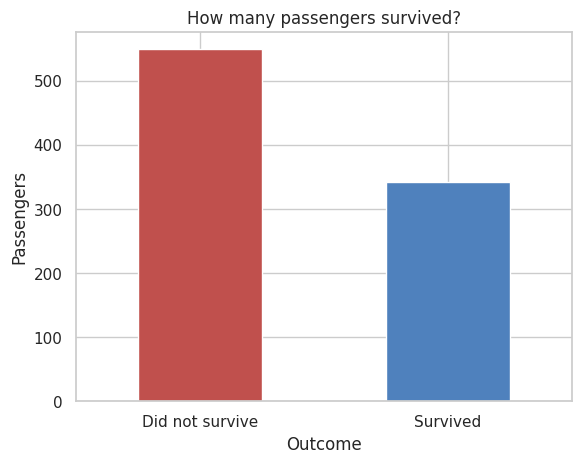

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df['Outcome'] = df['Survived'].map({0: 'Did not survive', 1: 'Survived'})
counts = df['Outcome'].value_counts()
ax = counts.plot(kind='bar', color=['#c0504d', '#4f81bd'], rot=0)
ax.set_title('How many passengers survived?')
ax.set_ylabel('Passengers')
plt.show()

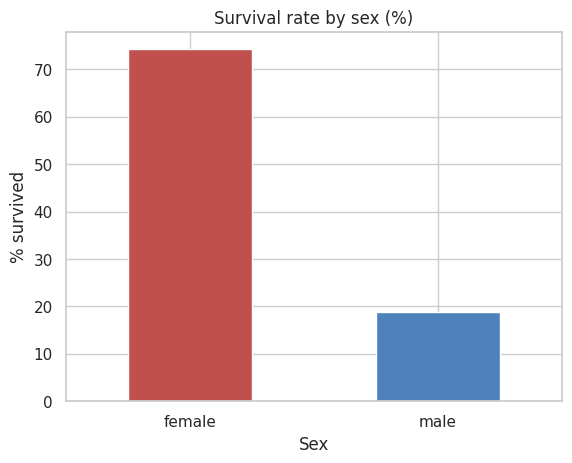

In [3]:
rate = df.groupby('Sex')['Survived'].mean() * 100
ax = rate.plot(kind='bar', color=['#c0504d', '#4f81bd'], rot=0)
ax.set_title('Survival rate by sex (%)')
ax.set_ylabel('% survived')
plt.show()

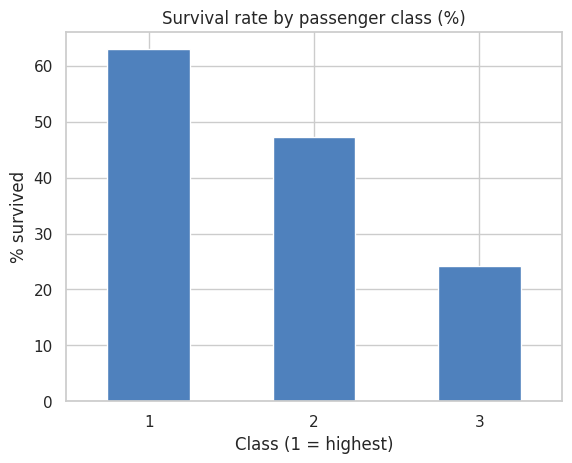

In [4]:
rate = df.groupby('Pclass')['Survived'].mean() * 100
ax = rate.plot(kind='bar', color='#4f81bd', rot=0)
ax.set_title('Survival rate by passenger class (%)')
ax.set_xlabel('Class (1 = highest)')
ax.set_ylabel('% survived')
plt.show()

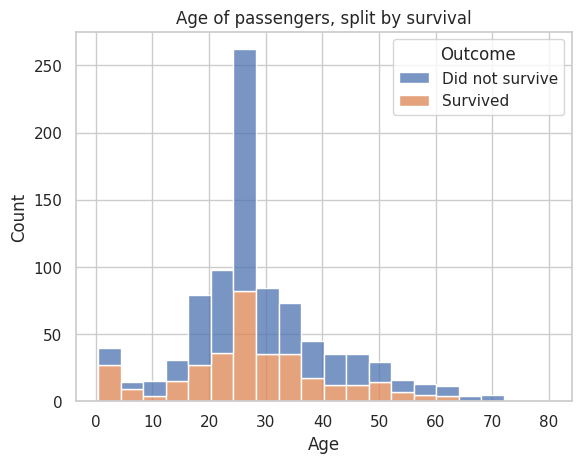

Average age: 29.4


In [5]:
ax = sns.histplot(data=df, x='Age', hue='Outcome', bins=20, multiple='stack')
ax.set_title('Age of passengers, split by survival')
plt.show()
print('Average age:', round(df['Age'].mean(), 1))

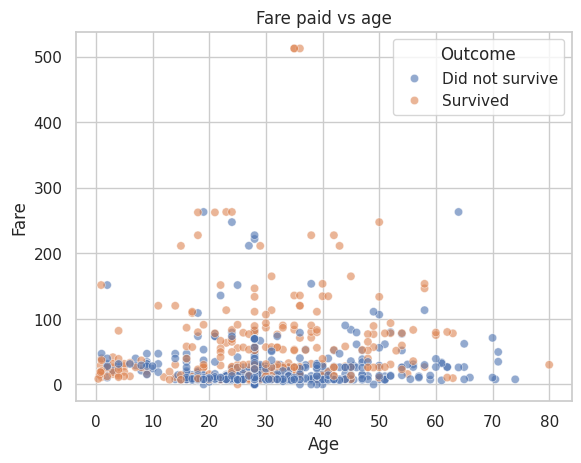

Correlation age-fare: 0.1


In [6]:
ax = sns.scatterplot(data=df, x='Age', y='Fare', hue='Outcome', alpha=0.6)
ax.set_title('Fare paid vs age')
plt.show()
print('Correlation age-fare:', round(df['Age'].corr(df['Fare']), 2))

## Interpretation

Chart 1 (survival count): 549 passengers did not survive and 342 did, about 38% survived. It does not explain why people survived.

Chart 2 (sex): About 74% of women survived vs about 19% of men. It does not prove sex alone caused survival, because class and age are mixed in.

Chart 3 (class): Survival was about 63% in 1st class, 47% in 2nd and 24% in 3rd. This shows a link, not a cause.

Chart 4 (age): Most passengers were aged 20 to 40, average age about 29. It does not prove age alone decided survival. Missing ages filled in during cleaning may affect the shape.

Chart 5 (fare vs age): The link is very weak (correlation 0.10). Correlation does not prove cause, and a few very high fares are outliers.

Conclusion: Survival differed by sex and class in this dataset. These charts show patterns, not causes.